<a href="https://colab.research.google.com/github/khushnoodh976-lab/telecom_churn_prediction/blob/main/ML_Project_Roadmap_By_Khushnood_Hassan.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
#----------Telecom Churn Prediction Project----------
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

SEED = 42
#----------1.Load----------
df = pd.read_csv("telecom_churn_raw.csv")
print("Raw shape:", df.shape)
print("Missing:\n", df.isna().sum())
print("Duplicates:", df.duplicated().sum())
print(df["contract_type"].value_counts(dropna=False))
print("Max changes:", df["monthly_charges"].max())


Raw shape: (65, 5)
Missing:
 contract_type      0
tenure_months      3
monthly_charges    4
support_tickets    0
churn              0
dtype: int64
Duplicates: 3
contract_type
Month-to-Month    34
One Year          18
Two Year          10
MONTH-TO-MONTH     3
Name: count, dtype: int64
Max changes: 743.4


In [2]:
#----------2.Clean----------
df = df.drop_duplicates().reset_index(drop=True)
#Fix Contract Text
df["contract_type"] = df["contract_type"].str.strip().str.title()
df["contract_type"] = df["contract_type"].replace({"Month_to_Month":"Month_to_Month"})
#Outlies > 150 = wrong, make it missing
df.loc[df["monthly_charges"] > 150, "monthly_charges"] = np.nan
#Fill missing with median(median is safe,mean is affected by outlier)
df["tenure_months"] = df["tenure_months"].fillna(df["tenure_months"].median())
df["monthly_charges"] = df["monthly_charges"].fillna(df["monthly_charges"].median())
print("\nClean shape:", df.shape)
print("Missing after clean:", df.isna().sum().sum())
print("Churn %:\n", df["churn"].value_counts(normalize=True) * 100)



Clean shape: (62, 5)
Missing after clean: 0
Churn %:
 churn
No     62.903226
Yes    37.096774
Name: proportion, dtype: float64


In [3]:
#----------3.EDA (Answer in numbers)----------
print("\n---Churn by contract(&)---")
print(df.groupby("contract_type")["churn"].apply(lambda s: (s=="Yes").mean()*100))
print("\n--- Average by Churn ---")
print(df.groupby("churn")[["tenure_months","monthly_charges"]].mean())
print("\n---Churn by support tickets(&)---")
df["tickets_group"] = df["support_tickets"].apply(lambda x: "3+" if x >= 3 else "0-2")
print(df.groupby("tickets_group")["churn"].apply(lambda s: (s=="Yes").mean()*100))
print("\n--- Churn by Tenure Group (%) ---")
df["tenure_group"] = pd.cut(df["tenure_months"], bins=[0,12,24,60], labels=["0-12","13-24","25-60"])
print(df.groupby("tenure_group", observed=True)["churn"].apply(lambda s: (s=="Yes").mean()*100))



---Churn by contract(&)---
contract_type
Month-To-Month    50.000000
One Year          27.777778
Two Year          10.000000
Name: churn, dtype: float64

--- Average by Churn ---
       tenure_months  monthly_charges
churn                                
No         34.000000        41.125641
Yes        20.608696        49.617826

---Churn by support tickets(&)---
tickets_group
0-2    31.372549
3+     63.636364
Name: churn, dtype: float64

--- Churn by Tenure Group (%) ---
tenure_group
0-12     58.333333
13-24    58.333333
25-60    23.684211
Name: churn, dtype: float64


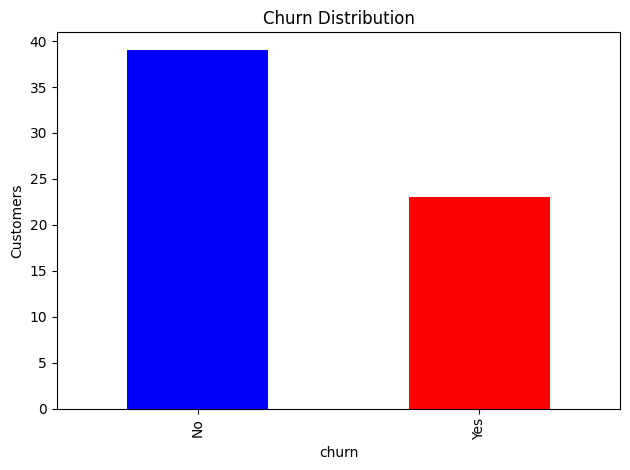

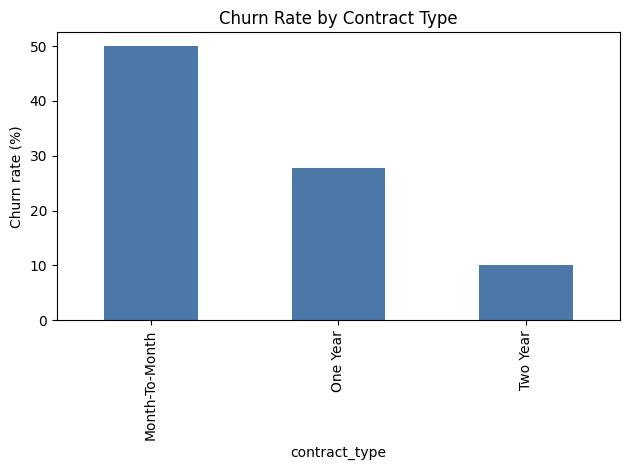

/tmp/ipykernel_4840/1817544912.py:19: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot([df[df.churn=="No"]["monthly_charges"], df[df.churn=="Yes"]["monthly_charges"]], labels=["Stayed","Churned"])


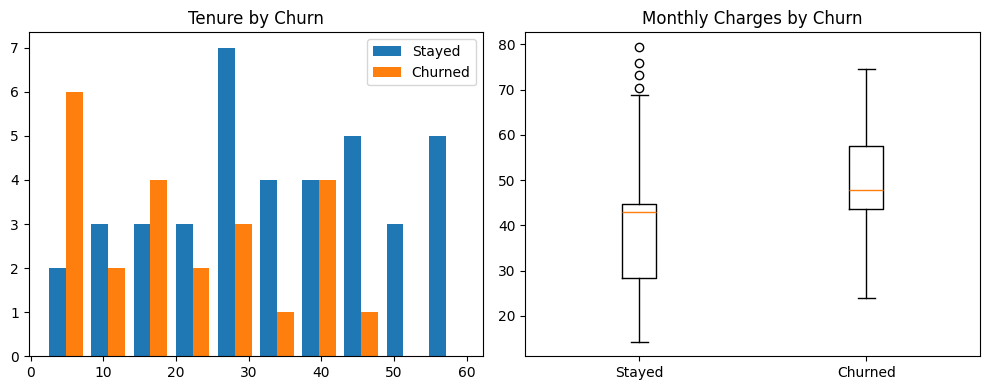

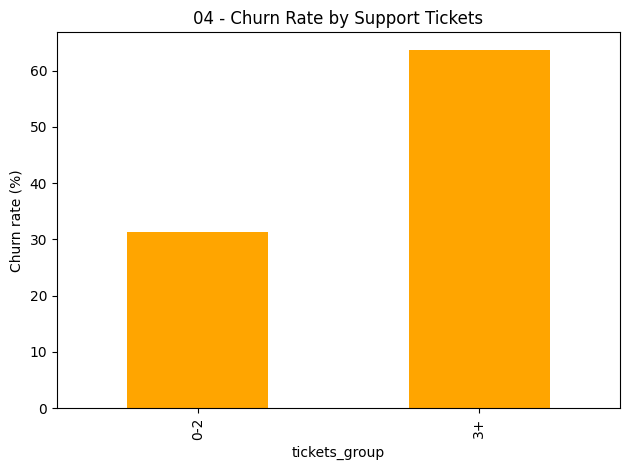

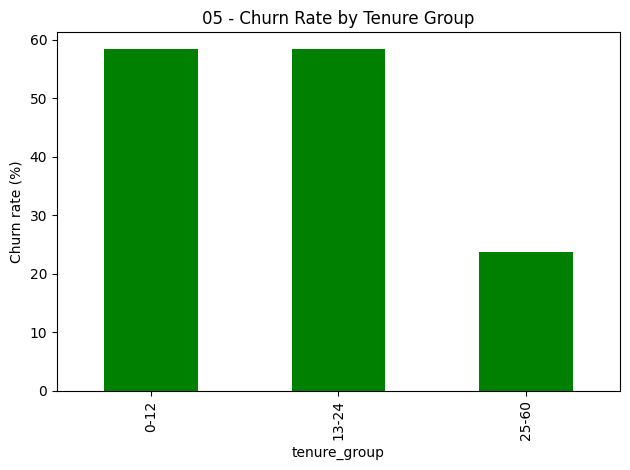

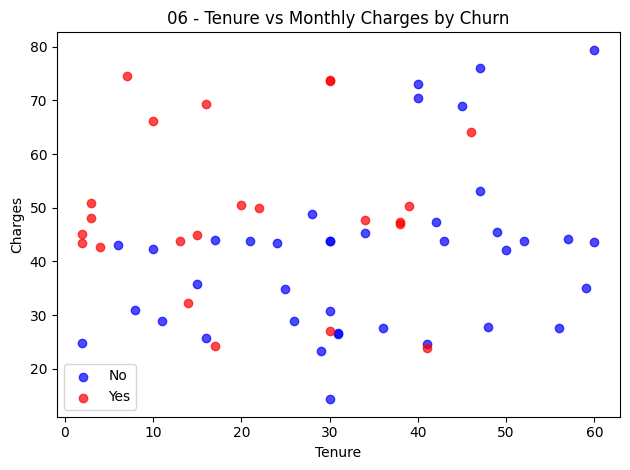


Charts saved: 01, 02, 03, 04, 05, 06


In [4]:
#----------4.Visualisation(Charts)----------
#Chart 1------(Churn Distribution)------
plt.figure()
df["churn"].value_counts().plot(kind="bar", color=["blue","red"])
plt.title("Churn Distribution")
plt.ylabel("Customers")
plt.tight_layout(); plt.show()
#Chart 2------(Churn Rate By Contract Type)------
rate = df.groupby("contract_type")["churn"].apply(lambda s: (s=="Yes").mean()*100)
plt.figure()
rate.plot(kind="bar", color="#4C78A8")
plt.title("Churn Rate by Contract Type")
plt.ylabel("Churn rate (%)")
plt.tight_layout(); plt.show()
#Chart 3------(Tenure By churn & Monthly Charges By Churn)------
fig, axes = plt.subplots(1,2, figsize=(10,4))
axes[0].hist([df[df.churn=="No"]["tenure_months"], df[df.churn=="Yes"]["tenure_months"]], bins=10, label=["Stayed","Churned"])
axes[0].set_title("Tenure by Churn"); axes[0].legend()
axes[1].boxplot([df[df.churn=="No"]["monthly_charges"], df[df.churn=="Yes"]["monthly_charges"]], labels=["Stayed","Churned"])
axes[1].set_title("Monthly Charges by Churn")
fig.tight_layout(); plt.show()
#Chart 4------(Churn Rate By Support Tickests)------
plt.figure(); df.groupby("tickets_group")["churn"].apply(lambda s: (s=="Yes").mean()*100).plot(kind="bar", color="orange")
plt.title("04 - Churn Rate by Support Tickets"); plt.ylabel("Churn rate (%)")
plt.tight_layout(); plt.show()
#Chart 5------(Churn Rate By Tenure Group)------
plt.figure(); df.groupby("tenure_group", observed=True)["churn"].apply(lambda s: (s=="Yes").mean()*100).plot(kind="bar", color="green")
plt.title("05 - Churn Rate by Tenure Group"); plt.ylabel("Churn rate (%)")
plt.tight_layout(); plt.show()
#Chart 6------(Tenure vs Monthly Charges By Churn)------
plt.figure()
for label, color in [("No","blue"),("Yes","red")]:
    sub = df[df.churn==label]
    plt.scatter(sub["tenure_months"], sub["monthly_charges"], label=label, alpha=0.7, color=color)
plt.title("06 - Tenure vs Monthly Charges by Churn"); plt.xlabel("Tenure"); plt.ylabel("Charges"); plt.legend()
plt.tight_layout(); plt.show()
print("\nCharts saved: 01, 02, 03, 04, 05, 06")


In [5]:
#----------5.Model----------
# Convert text to numbers
X = pd.get_dummies(df[["contract_type","tenure_months","monthly_charges","support_tickets"]],
                   columns=["contract_type"], drop_first=True, dtype=float)
y = (df["churn"] == "Yes").astype(int)  # Yes=1, No=0

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=SEED, stratify=y)

print(f"\nTrain: {len(X_train)}, Test: {len(X_test)}")



Train: 43, Test: 19


In [7]:
#----------6.Train + Evaluate----------
def evaluate(name, model):
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    print(f"\n{name}")
    print(f"Accuracy: {accuracy_score(y_test, pred):.3f}")
    print(f"Precision: {precision_score(y_test, pred, zero_division=0):.3f}")
    print(f"Recall: {recall_score(y_test, pred, zero_division=0):.3f}")
    print(f"F1: {f1_score(y_test, pred, zero_division=0):.3f}")
    print("Confusion Matrix:\n", confusion_matrix(y_test, pred))
    return model

m1 = evaluate("Logistic Regression", LogisticRegression(max_iter=1000))
m2 = evaluate("Random Forest", RandomForestClassifier(n_estimators=100, random_state=SEED))



Logistic Regression
Accuracy: 0.737
Precision: 0.625
Recall: 0.714
F1: 0.667
Confusion Matrix:
 [[9 3]
 [2 5]]

Random Forest
Accuracy: 0.842
Precision: 1.000
Recall: 0.571
F1: 0.727
Confusion Matrix:
 [[12  0]
 [ 3  4]]


In [8]:
# ----------7.Conclusion----------
print("\nCONCLUSION: Month-to-Month + many support tickets + short tenure = highest churn risk.")
print("Retention team should contact these customers first.")


CONCLUSION: Month-to-Month + many support tickets + short tenure = highest churn risk.
Retention team should contact these customers first.
